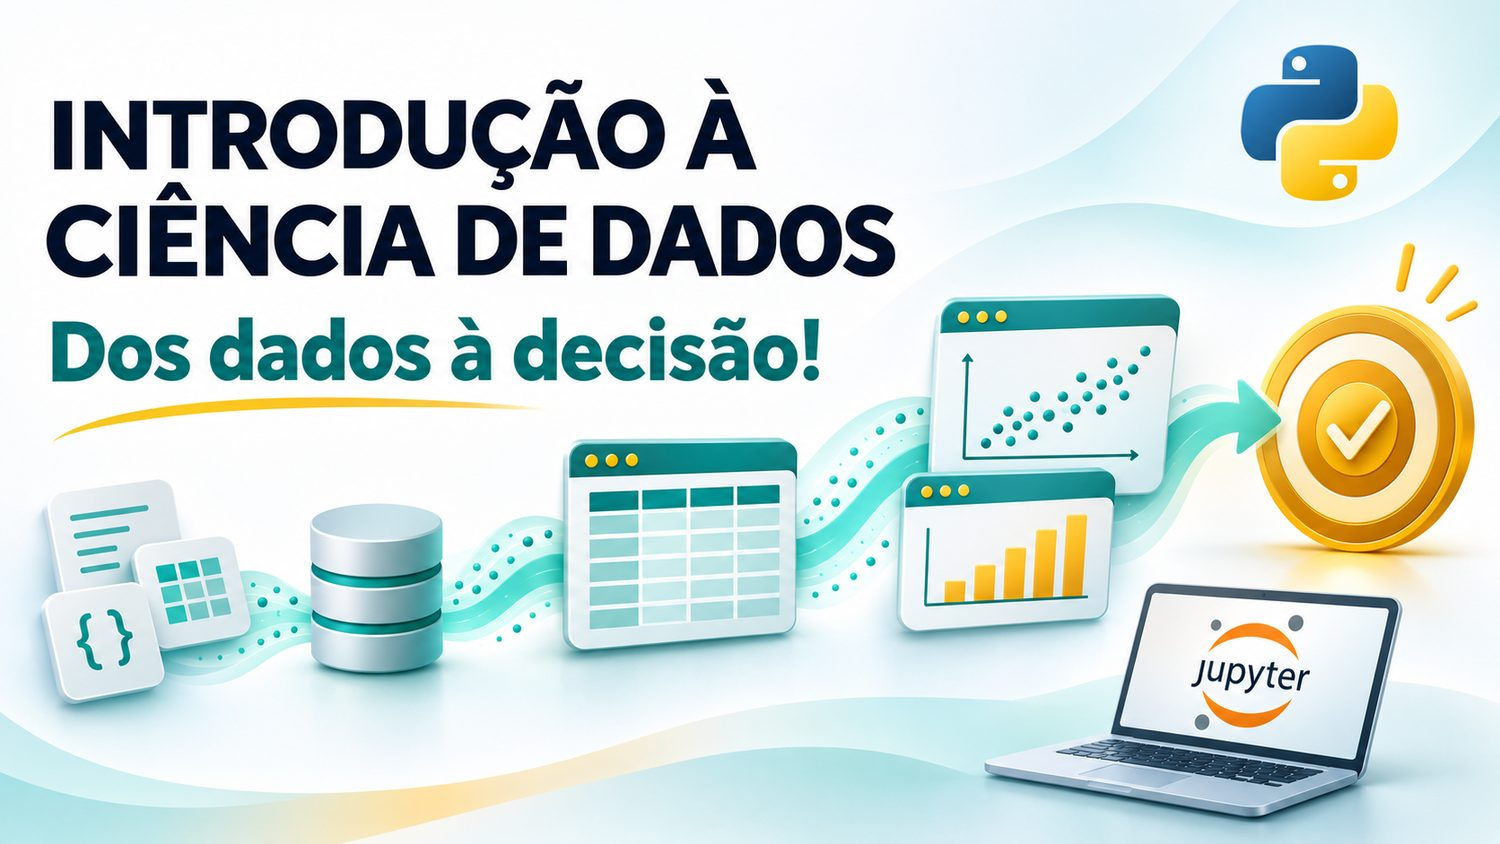

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_5_modelos_supervisionados/04_Arvores_de_Decisao.ipynb)

# Capítulo 4 – Árvores de decisão

Uma árvore de decisão prevê fazendo uma sequência de perguntas de sim ou não: «a entrega sai depois das 17h?», «tem mais de 6 km?». É o modelo que mais se parece com a forma como uma pessoa explicaria uma decisão, e por isso um dos mais fáceis de interpretar. Neste capítulo vemos como a árvore escolhe as perguntas, implementamos essa escolha de raiz e usamos árvores para classificação e para regressão.

> **Objetivos:** ler uma árvore de decisão; medir a impureza de um grupo com o índice de Gini; implementar a procura da melhor divisão; perceber o crescimento recursivo e as regiões retangulares; controlar a complexidade com a profundidade e o tamanho mínimo das folhas; usar árvores de regressão; interpretar a importância dos atributos; conhecer os pontos fortes e as limitações do método.

**Pré-requisitos:** capítulos 1 a 3. Para ir mais longe: [Árvores, florestas e boosting](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_3_ia/N3_15_Arvores_Florestas_Boosting.ipynb).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

In [2]:
def gerar_entregas(n=4000, semente=29):
    """Gera entregas de uma empresa fictícia de distribuição urbana (dados sintéticos)."""
    rng = np.random.default_rng(semente)
    distancia = rng.gamma(2.2, 2.6, n).clip(0.4, 25).round(1)
    hora = rng.uniform(8, 21, n).round(2)
    paragens = rng.poisson(1.2, n)
    peso = rng.gamma(1.6, 3.0, n).clip(0.1, 30).round(1)
    chuva = rng.random(n) < 0.2
    zona = rng.choice(["centro", "periferia", "rural"], n, p=[0.5, 0.35, 0.15])
    veiculo = np.where(distancia < 3, rng.choice(["bicicleta", "mota"], n, p=[0.6, 0.4]),
                       rng.choice(["mota", "carrinha"], n, p=[0.55, 0.45]))
    hora_de_ponta = ((hora >= 8) & (hora < 9.5)) | ((hora >= 17) & (hora < 19.5))
    transito = np.where(hora_de_ponta, np.where(zona == "centro", 1.75, 1.45), 1.0)
    por_km = np.select([veiculo == "bicicleta", veiculo == "mota"], [4.2, 2.9], 3.3)
    tempo = (7 + distancia * por_km * transito * np.where(chuva, 1.25, 1.0) * np.where(zona == "rural", 0.85, 1.0)
             + 4.0 * paragens + 0.15 * peso + rng.normal(0, 3.5, n))
    tempo = np.where(rng.random(n) < 0.015, tempo + rng.uniform(40, 120, n), tempo)       # avarias e enganos de morada
    prometido = 16 + 3.6 * distancia + 4.0 * paragens
    return pd.DataFrame({"distancia_km": distancia, "hora": hora, "paragens": paragens, "peso_kg": peso,
                         "chuva": chuva, "zona": zona, "veiculo": veiculo,
                         "tempo_min": tempo.clip(4).round(1), "atrasada": tempo > prometido})


entregas = gerar_entregas()
entregas.head()

,distancia_km,hora,paragens,peso_kg,chuva,zona,veiculo,tempo_min,atrasada
0,3.6,9.05,3,2.2,False,periferia,carrinha,35.7,False
1,4.3,16.95,0,12.8,False,centro,mota,25.3,False
2,5.1,14.79,1,3.9,True,periferia,carrinha,34.0,False
3,6.0,8.43,1,9.8,False,periferia,mota,44.0,True
4,7.2,14.07,0,2.4,False,centro,mota,33.5,False


## Ler uma árvore

Começamos com uma árvore pequena, treinada com a distância e a hora para prever o atraso.

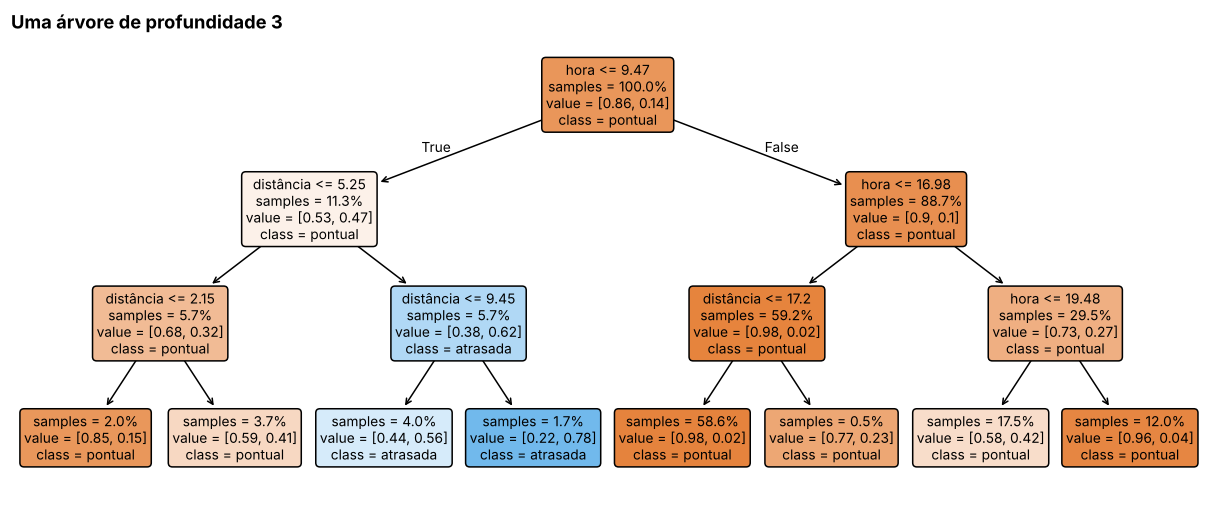

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

treino, resto = train_test_split(entregas, test_size=0.4, random_state=0, stratify=entregas["atrasada"])
validacao, teste = train_test_split(resto, test_size=0.5, random_state=0, stratify=resto["atrasada"])

dois = ["distancia_km", "hora"]
pequena = DecisionTreeClassifier(max_depth=3, random_state=0).fit(treino[dois], treino["atrasada"])

fig, ax = plt.subplots(figsize=(14, 5.4))
plot_tree(pequena, feature_names=["distância", "hora"], class_names=["pontual", "atrasada"], filled=True, rounded=True,
          impurity=False, proportion=True, precision=2, fontsize=9, ax=ax)
ax.set_title("Uma árvore de profundidade 3")
plt.show()

Cada caixa é um **nó**. Lê-se de cima para baixo:

| No desenho | Significado |
| --- | --- |
| Primeira linha (`hora <= …`) | A pergunta do nó. Se a resposta for **sim** (`True`), segue-se para a **esquerda**; se for não (`False`), para a direita |
| `samples` | A percentagem das entregas de treino que chega a este nó |
| `value` | A proporção de cada classe no nó: [pontuais, atrasadas] |
| `class` | A classe maioritária, que é a previsão se a entrega parar aqui |
| Cor | Laranja para «pontual», azul para «atrasada»; mais forte quanto mais puro é o nó |

O nó do topo é a **raiz** e contém todas as entregas. Os nós do fundo, sem pergunta, são as **folhas**: é aí que se faz a previsão. Para prever uma entrega nova, entra-se pela raiz e responde-se às perguntas até chegar a uma folha.

A árvore descobriu, sozinha, limiares próximos dos das horas de ponta. Uma regra como «depois das 17h, antes das 19h30 e com mais de alguns quilómetros → atrasada» lê-se diretamente do desenho. É a grande vantagem deste modelo: **a previsão vem com a explicação**.

## Como é que a árvore escolhe as perguntas?

A árvore procura a pergunta que deixa os dois grupos resultantes o mais **puros** possível: idealmente, todos os atrasos para um lado e todas as entregas pontuais para o outro.

### Medir a impureza: o índice de Gini

Para um grupo com uma proporção *p* de atrasos, o **índice de Gini** é 2 × p × (1 − p). No caso geral, com várias classes, é 1 − Σ pᵢ².

Tem uma leitura simples: é a probabilidade de duas entregas tiradas ao acaso do grupo serem de **classes diferentes**.

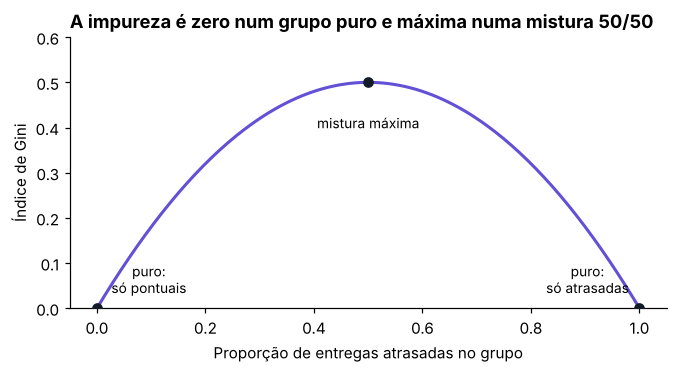

In [4]:
def gini(y):
    """Impureza de Gini de um grupo com alvo binário."""
    if len(y) == 0:
        return 0.0
    p = np.mean(y)
    return 2 * p * (1 - p)


p = np.linspace(0, 1, 200)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(p, 2 * p * (1 - p), color=VIOLETA, lw=2)
for proporcao, rotulo in [(0.0, "puro:\nsó pontuais"), (0.5, "mistura máxima"), (1.0, "puro:\nsó atrasadas")]:
    ax.scatter([proporcao], [2 * proporcao * (1 - proporcao)], color=TINTA, zorder=3)
    ax.annotate(rotulo, (proporcao, 2 * proporcao * (1 - proporcao)), textcoords="offset points",
                xytext={0.0: (34, 10), 0.5: (0, -30), 1.0: (-34, 10)}[proporcao], ha="center", fontsize=9)
ax.set_xlabel("Proporção de entregas atrasadas no grupo")
ax.set_ylabel("Índice de Gini")
ax.set_ylim(0, 0.6)
ax.set_title("A impureza é zero num grupo puro e máxima numa mistura 50/50")
plt.show()

### Avaliar uma pergunta

Uma pergunta divide um grupo em dois. A qualidade da divisão é a **impureza média dos dois grupos**, ponderada pelo tamanho de cada um. O **ganho** é quanto a impureza desceu em relação ao grupo original.

In [5]:
def impureza_da_divisao(x, y, limiar):
    """Impureza média ponderada depois de dividir por «x <= limiar»."""
    esquerda, direita = y[x <= limiar], y[x > limiar]
    return (len(esquerda) * gini(esquerda) + len(direita) * gini(direita)) / len(y)


y_treino = treino["atrasada"].to_numpy()
print(f"Impureza antes de qualquer pergunta: {gini(y_treino):.4f}")
for atributo, limiar in [("hora", 12.0), ("hora", 17.0), ("distancia_km", 5.0)]:
    depois = impureza_da_divisao(treino[atributo].to_numpy(), y_treino, limiar)
    print(f"  «{atributo} <= {limiar}»: impureza {depois:.4f}  |  ganho {gini(y_treino) - depois:.4f}")

Impureza antes de qualquer pergunta: 0.2474
  «hora <= 12.0»: impureza 0.2460  |  ganho 0.0014
  «hora <= 17.0»: impureza 0.2348  |  ganho 0.0126
  «distancia_km <= 5.0»: impureza 0.2417  |  ganho 0.0057


### Procurar a melhor pergunta

A árvore não adivinha: **experimenta todas**. Para cada atributo, testa todos os limiares possíveis (os pontos médios entre valores consecutivos) e fica com a pergunta de maior ganho.

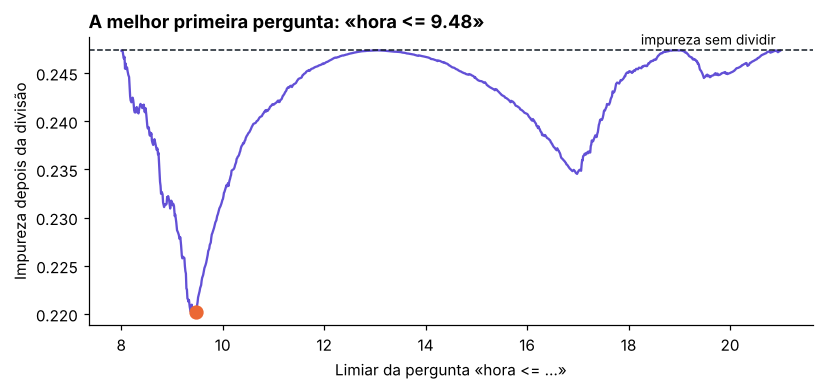

A nossa procura:  hora <= 9.475
O scikit-learn:   hora <= 9.475


In [6]:
def melhor_divisao(tabela, y, atributos):
    """Devolve (atributo, limiar, impureza) da melhor divisão de um nó."""
    melhor = (None, None, gini(y))
    for atributo in atributos:
        x = tabela[atributo].to_numpy()
        valores = np.unique(x)
        for limiar in (valores[:-1] + valores[1:]) / 2:
            impureza = impureza_da_divisao(x, y, limiar)
            if impureza < melhor[2]:
                melhor = (atributo, limiar, impureza)
    return melhor


horas = np.unique(treino["hora"])
limiares = (horas[:-1] + horas[1:]) / 2
impurezas = [impureza_da_divisao(treino["hora"].to_numpy(), y_treino, l) for l in limiares]
atributo, limiar, impureza = melhor_divisao(treino, y_treino, dois)

fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.plot(limiares, impurezas, color=VIOLETA, lw=1.5)
ax.axhline(gini(y_treino), color=TINTA, ls="--", lw=1)
ax.text(20.9, gini(y_treino) + 0.0006, "impureza sem dividir", ha="right", fontsize=9)
ax.scatter([limiar], [impureza], color=LARANJA, s=70, zorder=3)
ax.set_xlabel("Limiar da pergunta «hora <= …»")
ax.set_ylabel("Impureza depois da divisão")
ax.set_title(f"A melhor primeira pergunta: «{atributo} <= {limiar:.2f}»")
plt.show()

print(f"A nossa procura:  {atributo} <= {limiar:.3f}")
print(f"O scikit-learn:   {dois[pequena.tree_.feature[0]]} <= {pequena.tree_.threshold[0]:.3f}")

A curva mostra a impureza para cada limiar possível da hora. O mínimo corresponde à raiz da árvore do scikit-learn: a nossa procura encontrou a mesma pergunta.

### Repetir: a árvore cresce

Escolhida a primeira pergunta, o processo **repete-se em cada um dos dois grupos**, depois em cada um dos quatro, e assim por diante. Uma função que se chama a si própria para resolver partes mais pequenas do mesmo problema diz-se **recursiva** ([Funções](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_1_introducao/11_Funcoes.ipynb)).

In [7]:
def crescer(tabela, y, atributos, profundidade_maxima, profundidade=0):
    """Constrói uma árvore como dicionários encaixados."""
    atributo, limiar, _ = melhor_divisao(tabela, y, atributos)
    if profundidade == profundidade_maxima or atributo is None:
        return {"previsao": bool(np.mean(y) > 0.5), "n": len(y), "atrasadas": float(np.mean(y))}
    esquerda = (tabela[atributo] <= limiar).to_numpy()
    return {"pergunta": (atributo, float(limiar)),
            "sim": crescer(tabela[esquerda], y[esquerda], atributos, profundidade_maxima, profundidade + 1),
            "nao": crescer(tabela[~esquerda], y[~esquerda], atributos, profundidade_maxima, profundidade + 1)}


def mostrar(no, recuo=""):
    if "previsao" in no:
        print(f"{recuo}→ {'ATRASADA' if no['previsao'] else 'pontual'}  ({no['n']} entregas, {no['atrasadas']:.0%} atrasadas)")
        return
    atributo, limiar = no["pergunta"]
    print(f"{recuo}{atributo} <= {limiar:.2f}?")
    print(f"{recuo}  sim:")
    mostrar(no["sim"], recuo + "    ")
    print(f"{recuo}  não:")
    mostrar(no["nao"], recuo + "    ")


def prever(no, linha):
    while "previsao" not in no:
        atributo, limiar = no["pergunta"]
        no = no["sim"] if linha[atributo] <= limiar else no["nao"]
    return no["previsao"]


nossa = crescer(treino[dois], y_treino, dois, profundidade_maxima=2)
mostrar(nossa)

hora <= 9.48?
  sim:
    distancia_km <= 5.25?
      sim:
        → pontual  (136 entregas, 32% atrasadas)
      não:
        → ATRASADA  (136 entregas, 62% atrasadas)
  não:
    hora <= 16.98?
      sim:
        → pontual  (1420 entregas, 2% atrasadas)
      não:
        → pontual  (708 entregas, 27% atrasadas)


In [8]:
nossa3 = crescer(treino[dois], y_treino, dois, profundidade_maxima=3)
nossas = np.array([prever(nossa3, linha) for _, linha in validacao[dois].iterrows()])
print(f"Previsões iguais às da árvore do scikit-learn (profundidade 3): {(nossas == pequena.predict(validacao[dois])).mean():.1%}")

Previsões iguais às da árvore do scikit-learn (profundidade 3): 100.0%


Em cerca de quarenta linhas temos uma árvore de decisão que faz as mesmas previsões que a do scikit-learn. O algoritmo é **guloso**: em cada nó escolhe a melhor pergunta naquele momento, sem voltar atrás. Não garante a melhor árvore possível, mas é rápido e funciona bem.

## A árvore corta o espaço em retângulos

Cada pergunta é um corte **paralelo a um eixo**. A fronteira de decisão de uma árvore é por isso feita de retângulos.

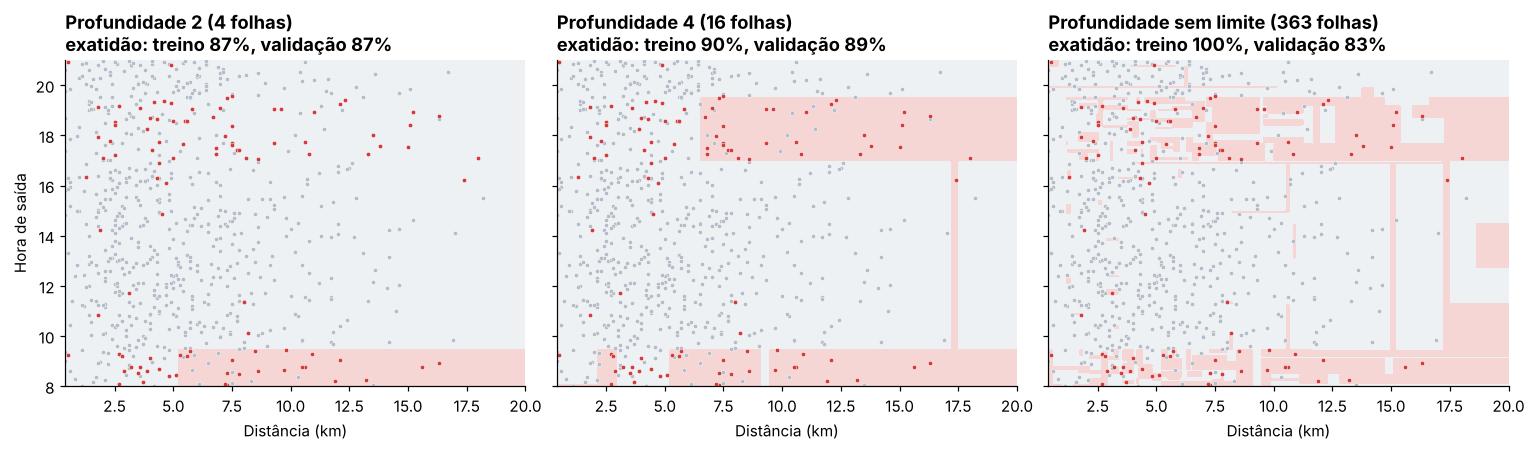

In [9]:
grelha_x, grelha_y = np.meshgrid(np.linspace(0.4, 20, 300), np.linspace(8, 21, 300))
grelha = pd.DataFrame({"distancia_km": grelha_x.ravel(), "hora": grelha_y.ravel()})
visiveis = treino.sample(700, random_state=1)

fig, eixos = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, profundidade in zip(eixos, [2, 4, None]):
    arvore = DecisionTreeClassifier(max_depth=profundidade, random_state=0).fit(treino[dois], treino["atrasada"])
    zona = arvore.predict(grelha).reshape(grelha_x.shape).astype(float)
    ax.contourf(grelha_x, grelha_y, zona, levels=[-0.5, 0.5, 1.5], colors=["#eef1f4", "#f6d5d5"])
    for valor, cor in [(False, CINZA), (True, MAU)]:
        d = visiveis[visiveis["atrasada"] == valor]
        ax.scatter(d["distancia_km"], d["hora"], s=8, color=cor, edgecolor="white", linewidth=0.3)
    rotulo = "sem limite" if profundidade is None else str(profundidade)
    ax.set_title(f"Profundidade {rotulo} ({arvore.get_n_leaves()} folhas)\nexatidão: treino {arvore.score(treino[dois], treino['atrasada']):.0%}, "
                 f"validação {arvore.score(validacao[dois], validacao['atrasada']):.0%}")
    ax.set_xlabel("Distância (km)")
    ax.set_xlim(0.4, 20)
eixos[0].set_ylabel("Hora de saída")
plt.tight_layout()
plt.show()

Compara com as fronteiras do KNN no capítulo 2. O padrão é o mesmo (duas faixas nas horas de ponta), mas aqui os limites são **linhas retas e nítidas**: a árvore encontrou as horas a que o trânsito muda.

Sem limite de profundidade, a árvore continua a dividir até cada folha ser pura. Acerta 100% do treino, isolando cada entrega atípica no seu pequeno retângulo, e piora na validação. É o mesmo fenómeno do KNN com k = 1.

## Controlar o crescimento

Uma árvore tem vários hiperparâmetros que limitam a sua complexidade.

| Hiperparâmetro | O que faz |
| --- | --- |
| `max_depth` | Número máximo de perguntas seguidas |
| `min_samples_leaf` | Número mínimo de casos numa folha; impede folhas com um ou dois casos |
| `min_samples_split` | Número mínimo de casos para um nó poder ser dividido |
| `max_leaf_nodes` | Número máximo de folhas |
| `ccp_alpha` | Poda: depois de crescer, corta os ramos que pouco contribuem |

A partir daqui usamos todos os atributos. Uma árvore **não precisa de normalização**: perguntar «distância <= 5 km» ou «distância <= 5000 m» dá a mesma divisão. Só os atributos nominais precisam de ser convertidos em números.

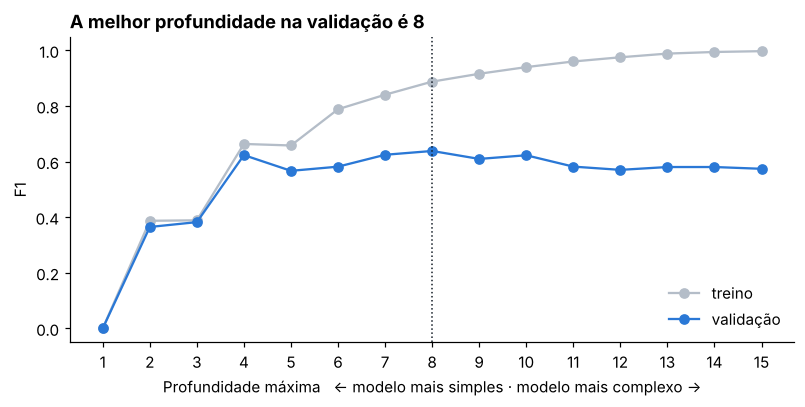

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

numericas, nominais = ["distancia_km", "hora", "paragens", "peso_kg", "chuva"], ["zona", "veiculo"]
todas = numericas + nominais


def preparacao():
    return ColumnTransformer([("cat", OneHotEncoder(), nominais)], remainder="passthrough", verbose_feature_names_out=False)


def arvore_completa(**opcoes):
    return make_pipeline(preparacao(), DecisionTreeClassifier(random_state=0, **opcoes)).fit(treino[todas], treino["atrasada"])


profundidades = list(range(1, 16))
curva = pd.DataFrame([{"profundidade": p,
                       "treino": f1_score(treino["atrasada"], (m := arvore_completa(max_depth=p)).predict(treino[todas])),
                       "validação": f1_score(validacao["atrasada"], m.predict(validacao[todas]))} for p in profundidades]).set_index("profundidade")
melhor_profundidade = int(curva["validação"].idxmax())

fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.plot(curva.index, curva["treino"], "o-", color=CINZA, label="treino")
ax.plot(curva.index, curva["validação"], "o-", color=AZUL, label="validação")
ax.axvline(melhor_profundidade, color=TINTA, ls=":", lw=1)
ax.set_xlabel("Profundidade máxima   ← modelo mais simples · modelo mais complexo →")
ax.set_ylabel("F1")
ax.set_xticks(profundidades)
ax.set_title(f"A melhor profundidade na validação é {melhor_profundidade}")
ax.legend(frameon=False, loc="lower right")
plt.show()

O desenho é o que já conhecemos, com o eixo ao contrário do do KNN: aqui a complexidade cresce para a **direita**. O treino melhora sempre; a validação melhora, estabiliza e depois perde terreno, à medida que a árvore começa a aprender casos particulares.

In [11]:
from sklearn.metrics import precision_score, recall_score

candidatos = {"Profundidade 1 (uma só pergunta)": arvore_completa(max_depth=1),
              f"Profundidade {melhor_profundidade}": arvore_completa(max_depth=melhor_profundidade),
              f"Profundidade {melhor_profundidade}, folhas com 10 ou mais casos": arvore_completa(max_depth=melhor_profundidade, min_samples_leaf=10),
              "Sem limites": arvore_completa()}
linhas = []
for nome, modelo in candidatos.items():
    previsto = modelo.predict(validacao[todas])
    linhas.append({"Árvore": nome, "folhas": modelo[-1].get_n_leaves(), "F1 no treino": f1_score(treino["atrasada"], modelo.predict(treino[todas])),
                   "F1 na validação": f1_score(validacao["atrasada"], previsto), "sensibilidade": recall_score(validacao["atrasada"], previsto),
                   "precisão": precision_score(validacao["atrasada"], previsto, zero_division=0)})
pd.DataFrame(linhas).set_index("Árvore").round(2)

,folhas,F1 no treino,F1 na validação,sensibilidade,precisão
Árvore,,,,,
Profundidade 1 (uma só pergunta),2,0.00,0.00,0.00,0.00
Profundidade 8,99,0.89,0.64,0.58,0.71
"Profundidade 8, folhas com 10 ou mais casos",63,0.78,0.65,0.57,0.76
Sem limites,206,1.00,0.57,0.55,0.59


A árvore sem limites tem cerca de duzentas folhas e um F1 perfeito no treino. A árvore limitada tem menos de um terço dessas folhas e é melhor em dados novos. Exigir um mínimo de casos por folha melhora sobretudo a precisão: deixa de haver avisos baseados em uma ou duas entregas. No capítulo 2, o melhor KNN ficou-se por um F1 perto de 0,5 na validação: a árvore, que usa todos os atributos sem se deixar confundir pelos inúteis, vai mais longe.

## Que atributos usou a árvore?

A **importância** de um atributo é a parte da redução total de impureza que se deve às perguntas feitas com ele. As importâncias somam 1.

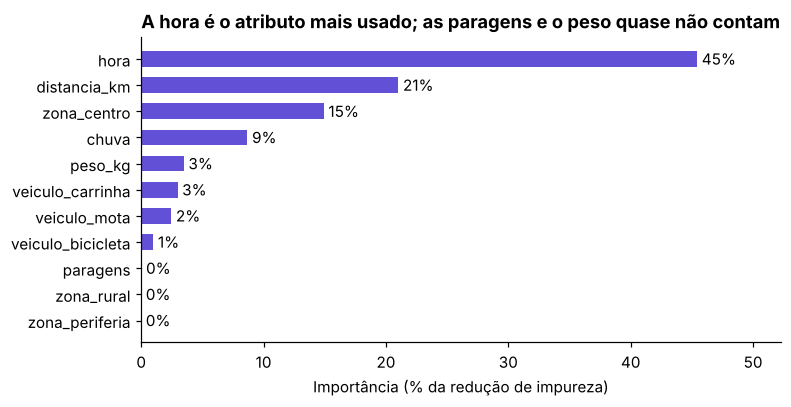

In [12]:
escolhida = candidatos[f"Profundidade {melhor_profundidade}, folhas com 10 ou mais casos"]
importancia = pd.Series(escolhida[-1].feature_importances_, index=escolhida[0].get_feature_names_out()).sort_values()

fig, ax = plt.subplots(figsize=(7.5, 3.6))
barras = ax.barh(importancia.index, importancia * 100, color=VIOLETA, height=0.6)
ax.bar_label(barras, fmt="%.0f%%", padding=3)
ax.set_xlim(0, importancia.max() * 115)
ax.set_xlabel("Importância (% da redução de impureza)")
ax.set_title("A hora é o atributo mais usado; as paragens e o peso quase não contam")
plt.show()

A árvore fez a **seleção de atributos** que no KNN tivemos de fazer à mão: as perguntas sobre o peso e as paragens quase nunca são as melhores, e por isso quase não aparecem.

Três cuidados ao ler este gráfico:

- a importância diz o que **este modelo** usou, e não o que causa os atrasos (módulo 1, capítulo 2);
- quando dois atributos trazem a mesma informação, a árvore usa um e o outro fica com importância baixa, mesmo sendo igualmente informativo;
- as importâncias mudam de uma árvore para outra, treinada com dados ligeiramente diferentes.

## Árvores de regressão

Para prever um número, muda-se duas coisas:

| | Classificação | Regressão |
| --- | --- | --- |
| A previsão de uma folha | A classe maioritária | A **média** dos valores na folha |
| A medida de impureza | Gini | A **variância** (o erro quadrático em relação à média da folha) |

O algoritmo é o mesmo: em cada nó, escolhe-se a pergunta que mais reduz a variância dentro dos dois grupos.

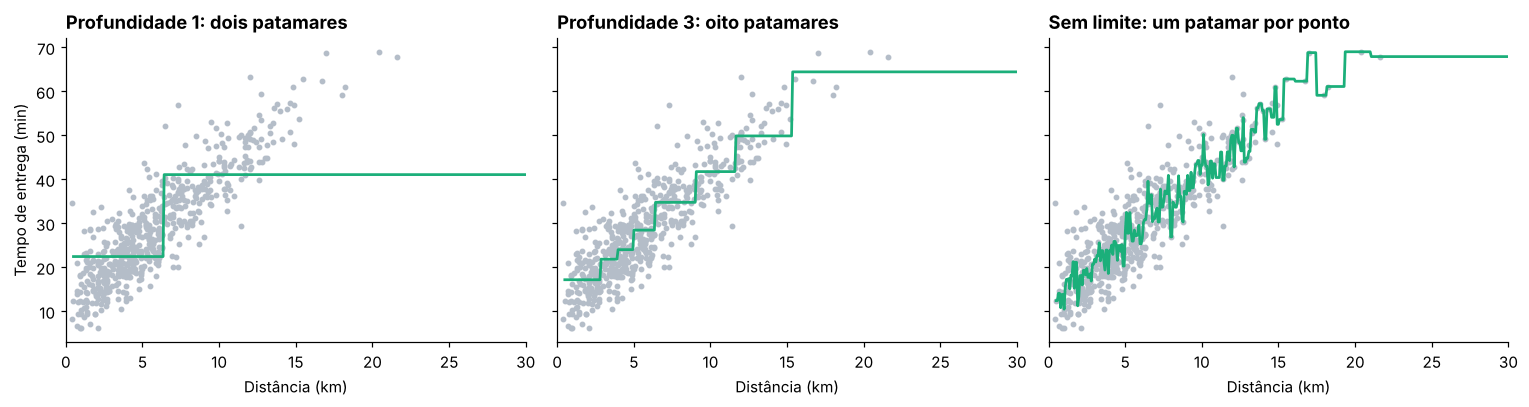

In [13]:
from sklearn.tree import DecisionTreeRegressor

calmas = treino[(treino["veiculo"] == "mota") & ~treino["chuva"] & treino["hora"].between(9.5, 17) & (treino["tempo_min"] < 90)]
X1, t1 = calmas[["distancia_km"]], calmas["tempo_min"]
pontos_novos = pd.DataFrame({"distancia_km": np.linspace(0.5, 30, 400)})

fig, eixos = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, profundidade in zip(eixos, [1, 3, None]):
    arvore = DecisionTreeRegressor(max_depth=profundidade, random_state=0).fit(X1, t1)
    ax.scatter(X1, t1, s=8, color=CINZA)
    ax.plot(pontos_novos, arvore.predict(pontos_novos), color=VERDE, lw=1.8)
    ax.set_xlabel("Distância (km)")
    ax.set_xlim(0, 30)
    ax.set_title({1: "Profundidade 1: dois patamares", 3: "Profundidade 3: oito patamares", None: "Sem limite: um patamar por ponto"}[profundidade])
eixos[0].set_ylabel("Tempo de entrega (min)")
plt.tight_layout()
plt.show()

A previsão de uma árvore de regressão é uma **escada**: um valor constante em cada folha. Com mais profundidade, mais degraus e mais estreitos. Sem limite, a escada passa por todos os pontos.

Repara no lado direito de cada gráfico: depois da última entrega de treino, a previsão fica horizontal. Tal como o KNN, **uma árvore não extrapola**.

Com todos os atributos:

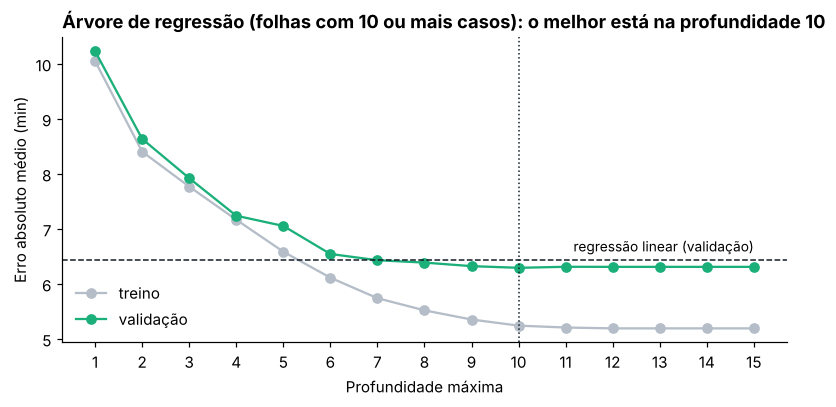

In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import StandardScaler


def arvore_regressao(**opcoes):
    return make_pipeline(preparacao(), DecisionTreeRegressor(random_state=0, min_samples_leaf=10, **opcoes)).fit(treino[todas], treino["tempo_min"])


curva_r = pd.DataFrame([{"profundidade": p,
                         "treino": mean_absolute_error(treino["tempo_min"], (m := arvore_regressao(max_depth=p)).predict(treino[todas])),
                         "validação": mean_absolute_error(validacao["tempo_min"], m.predict(validacao[todas]))} for p in profundidades]).set_index("profundidade")
melhor_r = int(curva_r["validação"].idxmin())
linear = make_pipeline(ColumnTransformer([("num", StandardScaler(), numericas), ("cat", OneHotEncoder(), nominais)]), LinearRegression()).fit(treino[todas], treino["tempo_min"])
mae_linear = mean_absolute_error(validacao["tempo_min"], linear.predict(validacao[todas]))

fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.plot(curva_r.index, curva_r["treino"], "o-", color=CINZA, label="treino")
ax.plot(curva_r.index, curva_r["validação"], "o-", color=VERDE, label="validação")
ax.axhline(mae_linear, color=TINTA, ls="--", lw=1)
ax.text(15, mae_linear + 0.15, "regressão linear (validação)", ha="right", fontsize=9)
ax.axvline(melhor_r, color=TINTA, ls=":", lw=1)
ax.set_xticks(profundidades)
ax.set_xlabel("Profundidade máxima")
ax.set_ylabel("Erro absoluto médio (min)")
ax.set_title(f"Árvore de regressão (folhas com 10 ou mais casos): o melhor está na profundidade {melhor_r}")
ax.legend(frameon=False, loc="lower left")
plt.show()

Exigimos pelo menos 10 entregas por folha. Sem esse limite, a árvore isolaria cada entrega com incidente na sua própria folha e passaria a prever tempos enormes para as entregas parecidas.

No erro médio, a melhor árvore fica ao nível da regressão linear, sem a bater com clareza. Mas os dois modelos erram de maneiras muito diferentes:

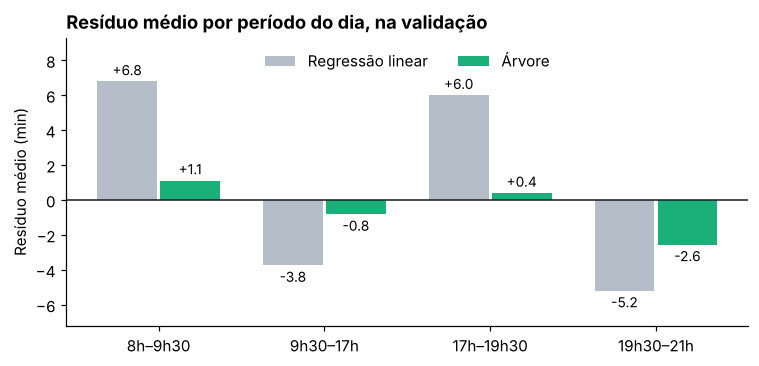

In [15]:
arvore_r = arvore_regressao(max_depth=melhor_r)
periodos = pd.cut(validacao["hora"], [8, 9.5, 17, 19.5, 21], labels=["8h–9h30", "9h30–17h", "17h–19h30", "19h30–21h"], include_lowest=True)
sem_incidente = validacao["tempo_min"] < validacao["tempo_min"].quantile(0.985)
residuos = pd.DataFrame({"Regressão linear": validacao["tempo_min"] - linear.predict(validacao[todas]),
                         "Árvore": validacao["tempo_min"] - arvore_r.predict(validacao[todas])})[sem_incidente]
media = residuos.groupby(periodos[sem_incidente], observed=True).mean()

fig, ax = plt.subplots(figsize=(8, 3.4))
posicoes = np.arange(len(media))
for i, (coluna, cor) in enumerate([("Regressão linear", CINZA), ("Árvore", VERDE)]):
    barras = ax.bar(posicoes + (i - 0.5) * 0.38, media[coluna], 0.36, color=cor, label=coluna)
    ax.bar_label(barras, fmt="%+.1f", padding=2, fontsize=9)
ax.axhline(0, color=TINTA, lw=1)
ax.set_xticks(posicoes, media.index)
ax.set_ylim(media.min().min() - 2, media.max().max() + 2.5)
ax.set_ylabel("Resíduo médio (min)")
ax.set_title("Resíduo médio por período do dia, na validação")
ax.legend(frameon=False, loc="upper center", ncol=2)
plt.show()

A árvore pode perguntar diretamente «a hora é anterior às 9h30?» e tratar esse grupo à parte. É por isso que o erro sistemático das horas de ponta, que a regressão linear não conseguia corrigir e o KNN só reduzia, fica aqui muito mais pequeno.

Então porque é que o erro médio não é melhor? Porque a árvore paga noutro lado: o tempo cresce com a distância de forma regular, e uma escada de patamares aproxima mal uma linha inclinada. A regressão linear faz isso na perfeição com um só coeficiente.

### O que a árvore ensina ao modelo linear

Cada modelo tem o que falta ao outro. E há uma maneira simples de juntar as duas coisas: **dar à regressão linear o que a árvore descobriu**. As primeiras perguntas da árvore dizem a que horas o trânsito muda. Com esses limiares criamos um atributo novo, `hora_de_ponta`, e o seu produto pela distância (a interação que vimos no exercício 4 do capítulo 1). É a engenharia de atributos do módulo 4, capítulo 5.

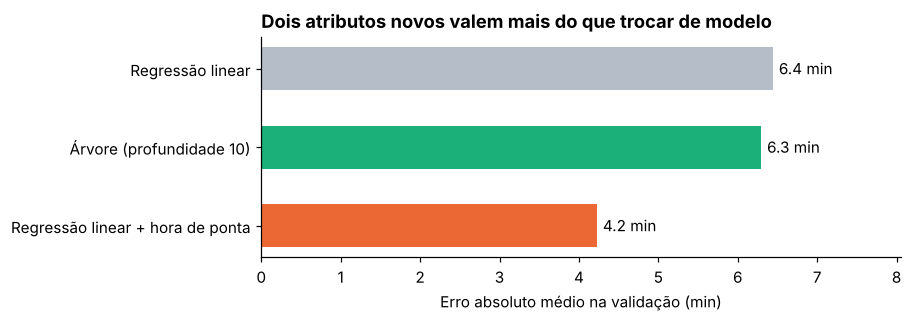

In [16]:
def com_hora_de_ponta(dados):
    ponta = dados["hora"].between(8, 9.5, inclusive="left") | dados["hora"].between(17, 19.5, inclusive="left")
    return dados.assign(hora_de_ponta=ponta.astype(float), km_em_hora_de_ponta=dados["distancia_km"] * ponta)


novas = numericas + ["hora_de_ponta", "km_em_hora_de_ponta"]
linear_melhorada = make_pipeline(ColumnTransformer([("num", StandardScaler(), novas), ("cat", OneHotEncoder(), nominais)]), LinearRegression())
linear_melhorada.fit(com_hora_de_ponta(treino), treino["tempo_min"])
mae_melhorada = mean_absolute_error(validacao["tempo_min"], linear_melhorada.predict(com_hora_de_ponta(validacao)))

fig, ax = plt.subplots(figsize=(7.5, 2.6))
nomes = ["Regressão linear", f"Árvore (profundidade {melhor_r})", "Regressão linear + hora de ponta"]
barras = ax.barh(nomes, [mae_linear, curva_r["validação"].min(), mae_melhorada], color=[CINZA, VERDE, LARANJA], height=0.55)
ax.bar_label(barras, fmt="%.1f min", padding=4)
ax.invert_yaxis()
ax.set_xlim(0, mae_linear * 1.25)
ax.set_xlabel("Erro absoluto médio na validação (min)")
ax.set_title("Dois atributos novos valem mais do que trocar de modelo")
plt.show()

O modelo mais simples, com dois atributos bem escolhidos, bate os outros por larga margem. É uma lição que se repete em muitos projetos:

> **Um bom atributo vale mais do que um modelo mais sofisticado.** E um modelo interpretável, como uma árvore pequena, é também uma ferramenta para descobrir bons atributos.

## Um defeito: a instabilidade

As árvores têm um ponto fraco importante: **mudam muito com pequenas mudanças nos dados**. Treinamos a mesma árvore em duas metades do treino.

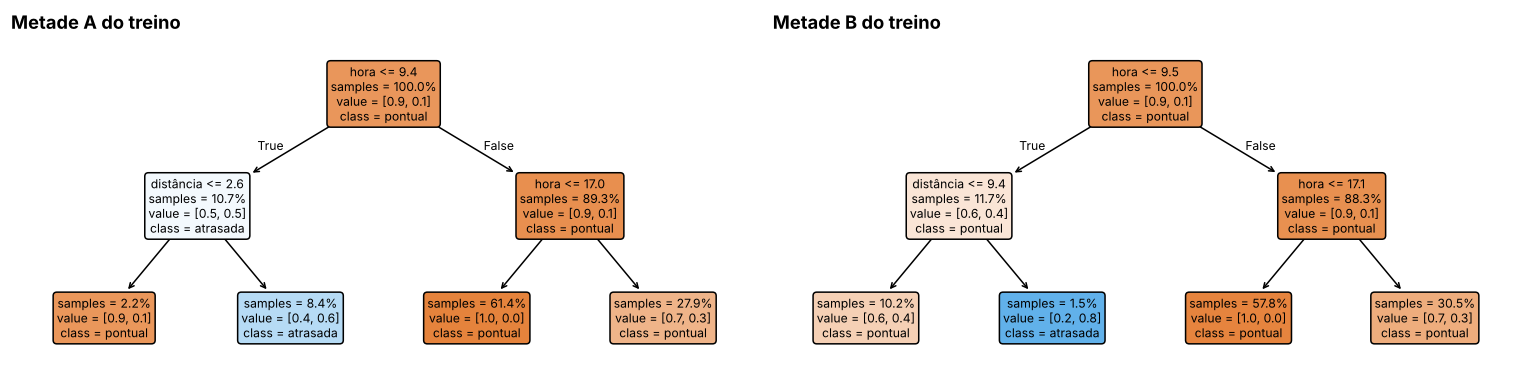

In [17]:
metade_a, metade_b = train_test_split(treino, test_size=0.5, random_state=3, stratify=treino["atrasada"])
fig, eixos = plt.subplots(1, 2, figsize=(14, 3.6))
for ax, metade, nome in [(eixos[0], metade_a, "Metade A"), (eixos[1], metade_b, "Metade B")]:
    arvore = DecisionTreeClassifier(max_depth=2, random_state=0).fit(metade[dois + ["paragens", "peso_kg"]], metade["atrasada"])
    plot_tree(arvore, feature_names=["distância", "hora", "paragens", "peso"], class_names=["pontual", "atrasada"], filled=True, rounded=True,
              impurity=False, proportion=True, precision=1, fontsize=8, ax=ax)
    ax.set_title(f"{nome} do treino")
plt.tight_layout()
plt.show()

As duas árvores foram treinadas com amostras dos mesmos dados e não fazem exatamente as mesmas perguntas: os limiares mudam, e por vezes muda o próprio atributo. Como cada pergunta condiciona todas as que vêm a seguir, uma pequena diferença no topo propaga-se por toda a árvore.

A solução mais usada é treinar **muitas árvores** em amostras diferentes dos dados e fazer a média das suas previsões. São as **florestas aleatórias** e o **boosting**, que estão entre os modelos mais usados em dados tabulares. Ficam fora deste tutorial; encontras uma introdução em [Árvores, florestas e boosting](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_3_ia/N3_15_Arvores_Florestas_Boosting.ipynb).

## O teste

In [18]:
previsto = escolhida.predict(teste[todas])
print(f"Árvore de classificação (profundidade {melhor_profundidade}, folhas com 10 ou mais casos), no teste:")
print(f"  exatidão {(previsto == teste['atrasada']).mean():.1%} | sensibilidade {recall_score(teste['atrasada'], previsto):.1%} | "
      f"precisão {precision_score(teste['atrasada'], previsto):.1%} | F1 {f1_score(teste['atrasada'], previsto):.2f} | "
      f"AUC {roc_auc_score(teste['atrasada'], escolhida.predict_proba(teste[todas])[:, 1]):.2f}")
print(f"Regressão (MAE no teste): árvore de profundidade {melhor_r}: {mean_absolute_error(teste['tempo_min'], arvore_r.predict(teste[todas])):.2f} min | "
      f"regressão linear: {mean_absolute_error(teste['tempo_min'], linear.predict(teste[todas])):.2f} min | "
      f"regressão linear + hora de ponta: {mean_absolute_error(teste['tempo_min'], linear_melhorada.predict(com_hora_de_ponta(teste))):.2f} min")

Árvore de classificação (profundidade 8, folhas com 10 ou mais casos), no teste:
  exatidão 91.6% | sensibilidade 55.2% | precisão 81.0% | F1 0.66 | AUC 0.86
Regressão (MAE no teste): árvore de profundidade 10: 6.63 min | regressão linear: 6.71 min | regressão linear + hora de ponta: 4.51 min


## Pontos fortes e limitações

| Pontos fortes | Limitações |
| --- | --- |
| Fácil de explicar e de desenhar | Instável: pequenas mudanças nos dados dão árvores diferentes |
| Não precisa de normalização | Sobreajusta facilmente se não for limitada |
| Ignora atributos irrelevantes | Previsões em patamares; não extrapola |
| Capta interações e efeitos não lineares | Cortes só paralelos aos eixos: uma fronteira oblíqua exige muitos degraus |
| Rápida a prever | Uma árvore sozinha raramente é o modelo mais exato |

## KNN ou árvore?

| | KNN | Árvore de decisão |
| --- | --- | --- |
| Ideia | Casos parecidos têm resultados parecidos | Sequência de perguntas de sim ou não |
| Treino | Nenhum (guarda os dados) | Constrói a árvore |
| Previsão | Lenta com muitos dados | Muito rápida |
| Escala dos atributos | Obrigatório normalizar | Indiferente |
| Atributos irrelevantes | Prejudicam | São ignorados |
| Complexidade controla-se com | k (maior = mais simples) | Profundidade (maior = mais complexo) |
| Explicação | «Parece-se com estes casos» | «Seguiu estas regras» |

## Exercícios

### `Exercício 1` – Gini à mão

Um nó tem 10 entregas: 4 atrasadas e 6 pontuais. A pergunta «chuva?» divide-o em dois grupos: com chuva (3 atrasadas, 1 pontual) e sem chuva (1 atrasada, 5 pontuais). Calcula a impureza do nó, a de cada grupo, a impureza ponderada depois da divisão e o ganho.

<details>
<summary><b>Ver uma solução possível</b></summary>

- Nó: 2 × 0,4 × 0,6 = **0,48**.
- Com chuva: 2 × 0,75 × 0,25 = 0,375.
- Sem chuva: 2 × (1/6) × (5/6) ≈ 0,278.
- Depois da divisão: (4 × 0,375 + 6 × 0,278) ÷ 10 ≈ **0,317**.
- Ganho: 0,48 − 0,317 ≈ **0,163**.

</details>

### `Exercício 2` – A entropia

Outra medida de impureza é a **entropia**: −p × log₂(p) − (1 − p) × log₂(1 − p). Escreve a função `entropia(y)` e desenha-a ao lado do Gini, para p entre 0 e 1. Depois treina duas árvores de profundidade 5 com `criterion="gini"` e `criterion="entropy"` e compara o F1 na validação.

In [19]:
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
def entropia(y):
    p = np.mean(y)
    return 0.0 if p in (0, 1) else float(-p * np.log2(p) - (1 - p) * np.log2(1 - p))


p = np.linspace(0.001, 0.999, 200)
plt.plot(p, 2 * p * (1 - p), label="Gini")
plt.plot(p, -p * np.log2(p) - (1 - p) * np.log2(1 - p), label="entropia")
plt.legend(); plt.show()

for criterio in ["gini", "entropy"]:
    m = arvore_completa(max_depth=5, criterion=criterio)
    print(criterio, round(f1_score(validacao["atrasada"], m.predict(validacao[todas])), 3))
```

As duas curvas têm a mesma forma: zero nos extremos e máximo em 0,5 (a entropia chega a 1, o Gini a 0,5). Na prática escolhem quase sempre as mesmas divisões, e os resultados são muito parecidos.

</details>

### `Exercício 3` – Variância de uma divisão

Adapta a função `impureza_da_divisao` para regressão: em vez do Gini, usa a variância (`np.var`). Procura o melhor limiar de `distancia_km` para dividir o alvo `tempo_min` no treino e compara com a raiz de uma `DecisionTreeRegressor(max_depth=1)` treinada só com esse atributo.

In [20]:
# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
x, alvo = treino["distancia_km"].to_numpy(), treino["tempo_min"].to_numpy()


def variancia_da_divisao(limiar):
    e, d = alvo[x <= limiar], alvo[x > limiar]
    return (len(e) * np.var(e) + len(d) * np.var(d)) / len(alvo)


valores = np.unique(x)
candidatos_limiar = (valores[:-1] + valores[1:]) / 2
melhor = candidatos_limiar[np.argmin([variancia_da_divisao(l) for l in candidatos_limiar])]
raiz = DecisionTreeRegressor(max_depth=1).fit(treino[["distancia_km"]], alvo)
print(f"A nossa procura: {melhor:.2f} km | scikit-learn: {raiz.tree_.threshold[0]:.2f} km")
```

Os dois limiares coincidem. A árvore de regressão é o mesmo algoritmo, com outra medida de impureza.

</details>

### `Exercício 4` – Ler as regras

Usa `export_text` (de `sklearn.tree`) para imprimir as regras de uma árvore de profundidade 3 treinada com todos os atributos. Escolhe uma folha que preveja «atrasada» e escreve a regra correspondente numa frase em português.

In [21]:
# Escreve aqui o código do exercício 4

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
from sklearn.tree import export_text

m = arvore_completa(max_depth=3)
print(export_text(m[-1], feature_names=list(m[0].get_feature_names_out()), decimals=1))
```

Cada caminho da raiz até uma folha é uma regra, por exemplo: «uma entrega que sai antes das 9h30, para o centro, com mais de 3,6 km, é prevista como atrasada». (Em `zona_centro <= 0.5`, a resposta «não» quer dizer que a zona é o centro.) Uma regra assim pode ser discutida com quem conhece a operação, o que é uma forma de validar o modelo que as métricas não dão.

</details>

## Verifica o que aprendeste

- [ ] Sei ler uma árvore de decisão e seguir uma previsão da raiz à folha.
- [ ] Sei calcular o índice de Gini de um grupo e o ganho de uma divisão.
- [ ] Sei explicar como a árvore procura a melhor pergunta.
- [ ] Sei porque a fronteira de uma árvore é feita de retângulos.
- [ ] Sei controlar a complexidade com a profundidade e o tamanho mínimo das folhas.
- [ ] Sei o que muda numa árvore de regressão.
- [ ] Sei ler as importâncias dos atributos, e os cuidados a ter.
- [ ] Sei comparar um KNN com uma árvore de decisão.

## Leitura recomendada

- https://scikit-learn.org/stable/modules/tree.html
- https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html
- https://en.wikipedia.org/wiki/Decision_tree_learning